# CSE558 Data Science — Midterm Project (DataMindz)
## What changes a mind on r/ChangeMyView? Raw dumps → cleaning → EDA → hypothesis testing

**Dataset:** the full r/ChangeMyView archive (Pushshift / ArcticShift per-subreddit dumps), Jan 2013 – Dec 2025
- `changemyview_submissions.zst` — 345,098 posts
- `changemyview_comments.zst` — 18,644,355 comments (4.2 GB compressed)

This notebook produces every number and figure in the report. Sections follow the report guidelines. Running it end to end takes about 5 minutes, most of it one pass over the comments file.

## 0. Setup

In [1]:
# pip install zstandard orjson pandas numpy scipy matplotlib
import io, re, time
from array import array
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import orjson, zstandard
import matplotlib.pyplot as plt
from scipy import stats

DATA_DIR = Path('~/Downloads/ds2026_reddit_data').expanduser()   # folder with the two .zst files
SUB_FILE = DATA_DIR / 'changemyview_submissions.zst'
COM_FILE = DATA_DIR / 'changemyview_comments.zst'
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

WINDOW = ('2017-04-01', '2022-12-01')   # posts created in [start, end): see Section 3.2
ALPHA = 0.05
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160)

In [2]:
REMOVED = {'[deleted]', '[removed]', ''}
WORD_RE = re.compile(r'\S+')
URL_RE  = re.compile(r'https?://|www\.', re.I)
CONFIRM_RE = re.compile(r'confirmed\W+1 delta awarded', re.I)
B36 = '0123456789abcdefghijklmnopqrstuvwxyz'

def to36(n):
    s = ''
    while n:
        n, r = divmod(n, 36); s = B36[r] + s
    return s or '0'

def stream(path):
    # read a .zst JSON-lines dump one record at a time; nothing is loaded whole
    with open(path, 'rb') as fh:
        reader = zstandard.ZstdDecompressor(max_window_size=2**31).stream_reader(fh)
        for line in io.TextIOWrapper(reader, encoding='utf-8', errors='replace'):
            if line.strip():
                try:
                    yield orjson.loads(line)
                except orjson.JSONDecodeError:
                    continue

def is_bot(name):
    name = name.lower()
    return name.endswith('bot') or name in {'automoderator', 'deltabot'}

---
## 1. Dataset overview

### 1.1 Where the data comes from
r/ChangeMyView (CMV) is a debate subreddit. A user posts a view they hold, titled `CMV: ...`, and others reply to change it. If a reply changes the original poster's (OP's) mind, the OP answers it with a **Δ (delta)** and an explanation, and **DeltaBot** replies "Confirmed: 1 delta awarded to /u/…". A delta is the community's own record of a changed mind, which makes CMV unusual: persuasion has a label.

The files are the per-subreddit Pushshift/ArcticShift dumps (one JSON object per line). Our team's first notebook read only the **first 2M comment lines**. The file is sorted by time, so that was not a sample: it was 2013–2015 only. Here we stream the **whole** file once instead, which is the streaming setting from Lecture 14: each record is read, a few numbers are kept, and the JSON is thrown away.

### 1.2 Submissions (all 345K)

In [3]:
t0 = time.time()
sub_fields, rows = set(), []
for d in stream(SUB_FILE):
    sub_fields.update(d.keys())
    pid = d.get('id')
    if not pid:
        continue
    text, author = (d.get('selftext') or '').strip(), d.get('author') or ''
    rows.append((int(pid, 36), author, int(float(d.get('created_utc') or 0)), bool(d.get('over_18')),
                 (d.get('title') or '').strip(), len(WORD_RE.findall(text)),
                 text in REMOVED or author in REMOVED, d.get('removed_by_category') or ''))
posts = pd.DataFrame(rows, columns=['pid', 'op', 'created', 'nsfw', 'title', 'post_words', 'post_removed', 'removed_by'])
del rows
print(f'Submissions: {len(posts):,} rows, {len(sub_fields)} distinct fields across the file ({time.time()-t0:.0f}s)')
print('Date range:', pd.to_datetime(posts.created.min(), unit='s').date(), 'to', pd.to_datetime(posts.created.max(), unit='s').date())

Submissions: 345,098 rows, 132 distinct fields across the file (6s)
Date range: 2013-01-17 to 2025-12-31


### 1.3 Comments (all 18.6M, one pass)
For every comment we keep its ID, parent, post, time, an author hash and two flags. Top-level replies (direct answers to the post) also keep their length, whether they contain a link, and whether a bot or moderator wrote them. Comments from 2023 on store IDs as base-10 integers instead of base-36 strings, so we convert them back.

In [4]:
op_of = dict(zip(posts.pid.values, posts.op.values))
cid, parent, parent_is_c, link, created = array('q'), array('q'), array('b'), array('q'), array('q')
author_h, is_op, removed = array('q'), array('b'), array('b')
top = []                 # (id, author, words, has_link, bot_or_mod)
confirm_parent = []      # comments DeltaBot confirmed a delta on (these are the OP's award messages)
com_fields, n = set(), 0

for d in stream(COM_FILE):
    n += 1
    if n % 100 == 0:
        com_fields.update(d.keys())
    if n % 3_000_000 == 0:
        print(f'  {n:,} comments ({time.time()-t0:.0f}s)')
    i, p, l = d.get('id'), d.get('parent_id'), d.get('link_id')
    if isinstance(l, int): l = 't3_' + to36(l)
    if isinstance(p, int): p = ('t3_' if l and p == int(l[3:], 36) else 't1_') + to36(p)
    if isinstance(i, int): i = to36(i)
    if not i or not p or not l:
        continue
    a, body = d.get('author') or '', d.get('body') or ''
    gone = body.strip() in REMOVED or a in REMOVED
    ci, lid, reply_to_comment = int(i, 36), int(l[3:], 36), p.startswith('t1_')
    if a == 'DeltaBot' and reply_to_comment and CONFIRM_RE.search(body):
        confirm_parent.append(int(p[3:], 36))
    cid.append(ci); parent.append(int(p[3:], 36)); parent_is_c.append(reply_to_comment); link.append(lid)
    created.append(int(float(d.get('created_utc') or 0))); author_h.append(0 if a in REMOVED else hash(a))
    is_op.append(a not in REMOVED and op_of.get(lid) == a); removed.append(gone)
    if not reply_to_comment:
        top.append((ci, a, 0 if gone else len(WORD_RE.findall(body)), bool(URL_RE.search(body)) and not gone,
                    is_bot(a) or d.get('distinguished') == 'moderator'))

E = pd.DataFrame({'id': np.frombuffer(cid, np.int64), 'parent': np.frombuffer(parent, np.int64),
                  'parent_is_c': np.frombuffer(parent_is_c, np.int8).astype(bool),
                  'link': np.frombuffer(link, np.int64), 'created': np.frombuffer(created, np.int64),
                  'author_h': np.frombuffer(author_h, np.int64),
                  'is_op': np.frombuffer(is_op, np.int8).astype(bool),
                  'removed': np.frombuffer(removed, np.int8).astype(bool)})
TOP = pd.DataFrame(top, columns=['id', 'author', 'words', 'has_link', 'bot_or_mod']).drop_duplicates('id')
del cid, parent, parent_is_c, link, created, author_h, is_op, removed, top
print(f'Comments: {n:,} rows, {len(com_fields)} distinct fields ({time.time()-t0:.0f}s)')

  3,000,000 comments (30s)


  6,000,000 comments (55s)


  9,000,000 comments (81s)


  12,000,000 comments (110s)


  15,000,000 comments (137s)


  18,000,000 comments (167s)


Comments: 18,644,355 rows, 81 distinct fields (176s)


---
## 2. Raw data inspection

In [5]:
print('A few raw posts:')
display(posts.assign(id=posts.pid.map(to36), date=pd.to_datetime(posts.created, unit='s').dt.date)
        [['id', 'date', 'title', 'post_words', 'nsfw', 'post_removed']].head(3))
n_dup = int(E.duplicated('id').sum())
E = E.drop_duplicates('id').reset_index(drop=True)
print(f'Duplicate comment IDs: {n_dup:,} (dropped, first copy kept)')
print(f'Post text removed or deleted: {posts.post_removed.mean():.1%} of all posts')
print('Why posts were removed (only recorded from 2019):', posts.removed_by.replace('', 'not recorded').value_counts().head(4).to_dict())
yr = pd.to_datetime(posts.created, unit='s').dt.year
display(pd.DataFrame({'posts': posts.groupby(yr).size(),
                      'comments': E.groupby(pd.to_datetime(E.created, unit='s').dt.year).size()}).T)

A few raw posts:


,id,date,title,post_words,nsfw,post_removed
0,16s77g,2013-01-17,I feel that becoming successful as a musician ...,75,False,False
1,16s6sq,2013-01-17,I think all language is inherently metaphorica...,40,False,False
2,16s6jg,2013-01-17,"The town of Oxford Hills is a shithole, CMV pl...",39,False,False


Duplicate comment IDs: 2,508 (dropped, first copy kept)
Post text removed or deleted: 65.8% of all posts
Why posts were removed (only recorded from 2019): {'not recorded': 215272, 'moderator': 80039, 'deleted': 40979, 'reddit': 7853}


created,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
posts,16952,19955,16422,16587,21366,32289,30861,42258,33844,24753,22976,28601,38234
comments,670553,895894,704759,706898,906645,1220052,1155716,1678445,1955693,1564463,1714767,2441547,3026415


---
## 3. Data preparation

### 3.1 Building the outcome: who won a delta?
The data has no "delta" column. A Δ character on its own is unreliable (people quote it, and the rules text and bot notices contain it), so we follow DeltaBot's confirmations instead:

1. DeltaBot says *"Confirmed: 1 delta awarded"* in reply to some comment *m*.
2. *m* must be written by the **OP** (anyone can award a delta; we only want the OP's) and must reply to another comment *x*. Then *x* was awarded.
3. A delta often comes after a back-and-forth: someone opens a branch with a top-level reply, the OP pushes back, and the delta lands on the challenger's 2nd or 3rd comment. So we walk *x* up to its top-level reply *r*. **The opening reply *r* won** if *x = r* or *x* has the same author as *r*.

In [6]:
idx = pd.Index(E.id.values)
conf = np.unique(np.array(confirm_parent, dtype=np.int64))
pos = idx.get_indexer(conf)
msg = E.iloc[pos[pos >= 0]]
chain = {'DeltaBot confirmations': len(confirm_parent), 'confirmed message found in archive': len(msg)}
msg = msg[msg.is_op & msg.parent_is_c]
chain['written by the OP, replying to a comment'] = len(msg)
awarded = np.unique(msg.parent.values)
chain['awarded comments'] = len(awarded)
awarding_posts = set(msg.link.values)          # threads where the OP gave at least one delta

# walk every awarded comment up to the top-level reply that opened its branch
root = awarded.copy()
for _ in range(1000):
    p = idx.get_indexer(root)
    deeper = np.zeros(len(root), bool); deeper[p >= 0] = E.parent_is_c.values[p[p >= 0]]
    if not deeper.any():
        break
    root[deeper] = E.parent.values[p[deeper]]
a_auth = E.author_h.values[idx.get_indexer(awarded)]
r_pos = idx.get_indexer(root)
r_auth = np.where(r_pos >= 0, E.author_h.values[r_pos], -1)
direct = awarded == root
same_author = ~direct & (a_auth == r_auth) & (a_auth != 0)
won_openers = set(root[direct | same_author])
chain['... on the top-level reply itself'] = int(direct.sum())
chain["... later in the branch, by the opener's author"] = int(same_author.sum())
chain['... later in the branch, by someone else (not counted)'] = int((~direct & ~same_author).sum())
chain['top-level replies that won'] = len(won_openers)
pd.Series(chain).to_frame('count').style.format('{:,}')

,count
DeltaBot confirmations,"137,226"
confirmed message found in archive,"136,573"
"written by the OP, replying to a comment","101,376"
awarded comments,"101,306"
... on the top-level reply itself,"57,031"
"... later in the branch, by the opener's author","26,573"
"... later in the branch, by someone else (not counted)","17,702"
top-level replies that won,"82,545"


Counting only direct awards would call about 26K openers losers even though their author changed the OP's mind a few comments later.

### 3.2 Choosing the time window
A test compares groups, so the rules of the game should not change halfway through the data. We looked for changes in (a) how deltas are recorded, (b) the community's rules, and (c) how the archive was collected. The subreddit's own mod posts date the main events, and the share of OPs who award any delta shows where the data is stable:

In [7]:
posts['intact'] = ~posts.post_removed
posts['op_awarded'] = posts.pid.isin(awarding_posts)
posts['is_cmv'] = posts.title.str.match(r'(?i)^\s*cmv')
events = posts[posts.title.str.contains(r'(?i)deltabot|delta ?log|chatgpt|ai-generated|unauthorized experiment')
               & posts.title.str.contains(r'(?i)mod post|meta')]
display(events.assign(date=pd.to_datetime(events.created, unit='s').dt.date)[['date', 'title']]
        .sort_values('date').reset_index(drop=True).style.hide(axis='index'))

date,title
2013-02-25,"[MOD POST] New ""delta points"" system and /u/DeltaBot. Let us know what you think."
2013-05-05,"[MOD POST] DeltaBot crashed during the huge rise in traffic, please link me to any missed deltas you know of."
2013-06-22,[MOD POST] We are looking for someone to be the programmer of DeltaBot!
2013-08-28,[MOD POST] A discussion of TCMV Tuesdays/Deltas and a continued search for DeltaBot Programmers/Wiki Contributors!
2013-09-18,[Mod Post] DeltaBot programmers needed! (Link to the code inside)
2014-05-15,"[Mod Post] Follow us on twitter @redditcmv for a live feed of new CMV posts. Also, DeltaBot is playing up."
2015-03-10,[Mod Post] Announcement: DeltaBot needs your help!
2015-04-30,[Mod Post] A call for help to fix and finish our DeltaBot.
2015-05-13,[Mod Post] DeltaBot is (still) down
2015-06-24,"[Meta] Deltabot is down, but your Deltas are being saved!"


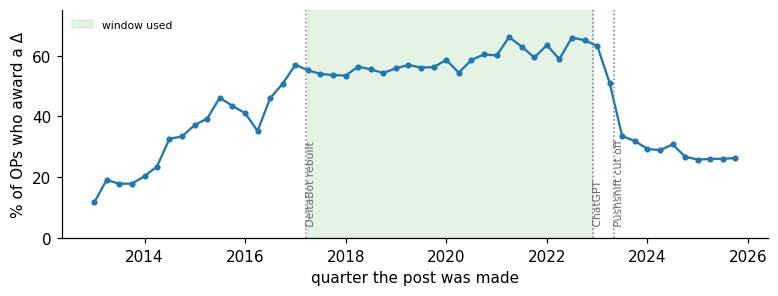

Inside the window the share stays between 53% and 66% every quarter.
Takeaway: before 2017 the share climbs while DeltaBot keeps missing deltas; after mid-2023 it halves when the archive changes hands. Between them it is flat.


In [8]:
q = pd.to_datetime(posts.created, unit='s').dt.to_period('Q')
share = posts[posts.intact & posts.is_cmv].groupby(q).op_awarded.mean()
x = share.index.to_timestamp()
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.axvspan(pd.Timestamp(WINDOW[0]), pd.Timestamp(WINDOW[1]), color='tab:green', alpha=.12, label='window used')
ax.plot(x, 100 * share.values, marker='o', ms=3, color='tab:blue')
for d, lab in [('2017-03-15', 'DeltaBot rebuilt'), ('2022-11-30', 'ChatGPT'), ('2023-05-01', 'Pushshift cut off')]:
    ax.axvline(pd.Timestamp(d), color='grey', ls=':', lw=1)
    ax.text(pd.Timestamp(d), 3, ' ' + lab, rotation=90, fontsize=7, color='dimgrey', va='bottom')
ax.set_ylim(0, 75); ax.set_ylabel('% of OPs who award a Δ'); ax.set_xlabel('quarter the post was made')
ax.legend(loc='upper left', fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / 'op_award_share.png', dpi=220); plt.show()
w = share[(x >= WINDOW[0]) & (x < WINDOW[1])]
print(f'Inside the window the share stays between {w.min():.0%} and {w.max():.0%} every quarter.')
print('Takeaway: before 2017 the share climbs while DeltaBot keeps missing deltas; after mid-2023 it halves when the archive changes hands. Between them it is flat.')

**Window: posts made from 1 April 2017 to 30 November 2022.**
- *Start.* DeltaBot was introduced in Feb 2013 but kept crashing ("DeltaBot is (still) down", 2015; "on vacation, message the moderators", 2016). It was rebuilt in early 2017 and on 15 Mar 2017 the mods announced it "should now, in theory, never miss a delta". Before that, a missing delta can mean a missed bot reply, not an unconvinced OP. We start at the first full month after.
- *End.* ChatGPT was released on 30 Nov 2022. By Feb 2023 the mods were discussing ChatGPT-written comments, in Oct 2024 they added a rule on AI content, and in 2025 they disclosed an unauthorised AI-persuasion experiment run on the subreddit. Pushshift lost API access in May 2023 and the archive moved to ArcticShift, which records removed posts differently (the jump in the figure). We stop before all of this.
- In between, the delta rules and the posting rules (A–E for posts, 1–5 for comments) were in place throughout; the mod posts in the window are clarifications and recruitment, not new rules.

### 3.3 Which threads we keep

In [9]:
start, end = (pd.Timestamp(s).timestamp() for s in WINDOW)
funnel = [('All posts', len(posts))]
P = posts[(posts.created >= start) & (posts.created < end)];  funnel.append(('posted inside the window', len(P)))
P = P[P.is_cmv];                                              funnel.append(('title starts with "CMV" (drops mod/meta posts)', len(P)))
P = P[~P.nsfw];                                               funnel.append(('not marked NSFW', len(P)))
removed_threads = P[~P.intact]
P = P[P.intact];                                              funnel.append(('post text and OP account intact', len(P)))
THREADS = P.copy()                                            # used for Test 4
P = P[P.op_awarded];                                          funnel.append(('OP awarded at least one delta', len(P)))
display(pd.DataFrame(funnel, columns=['step', 'posts']).style.format({'posts': '{:,}'}).hide(axis='index'))

n_top = E[~E.parent_is_c].groupby('link').size()
rt = removed_threads.pid.map(n_top).fillna(0)
print(f'Removed threads: median {rt.median():.0f} top-level replies, {(rt <= 2).mean():.0%} have 2 or fewer; '
      f'an OP delta appears in {removed_threads.op_awarded.mean():.1%} of them vs {THREADS.op_awarded.mean():.1%} of intact threads.')

step,posts
All posts,"345,098"
posted inside the window,"178,554"
"title starts with ""CMV"" (drops mod/meta posts)","155,890"
not marked NSFW,"154,564"
post text and OP account intact,"44,160"
OP awarded at least one delta,"25,447"


Removed threads: median 1 top-level replies, 59% have 2 or fewer; an OP delta appears in 1.2% of them vs 57.6% of intact threads.


- **Title starts with "CMV".** CMV's posting rules require it, so anything else is a mod announcement, a "Fresh Topic Friday" notice or a meta thread, not a view.
- **NSFW.** Reddit hides NSFW posts from many users, so these few threads get a different audience. A small, cheap filter.
- **Removed posts are not missing at random** (Lecture 3). Most were taken down by moderators for breaking the posting rules within minutes, so they have almost no replies and almost never an OP delta (numbers above). The rest were deleted by their author, which also erases the OP's name, so we cannot tell which awards came from the OP. Imputing makes no sense here; we drop them.
- **OP awarded at least one delta.** Many OPs post and leave. In those threads no reply wins, but no reply was really judged either. Keeping only threads where the OP gave a delta means every reply was read by an OP who was willing to be persuaded; this is also the restriction Tan et al. (2016) use for their within-thread comparisons. The threads we drop here are kept for Test 4, which asks which OPs award at all.

### 3.4 Which replies we keep

In [10]:
pc = P.set_index('pid')
R = E[~E.parent_is_c & E.link.isin(pc.index)].merge(TOP, on='id', how='left')
steps = [('deleted or removed reply', R.removed),
         ("OP's own top-level comment", R.is_op),
         ('bot or moderator notice', R.bot_or_mod.fillna(False).astype(bool)),
         ('fewer than 10 words', R.words < 10)]
funnel2, keep = [('Top-level replies in kept threads', len(R))], pd.Series(True, index=R.index)
for name, m in steps:
    m = m & keep; funnel2.append(('  minus ' + name, int(m.sum()))); keep &= ~m
A = R[keep].copy()
A['won'] = A.id.isin(won_openers).astype(int)
A['post_created'] = A.link.map(pc.created)
A['delay_h'] = (A.created - A.post_created) / 3600
A['post_words'] = A.link.map(pc.post_words)
A['year'] = pd.to_datetime(A.post_created, unit='s').dt.year
A = A[['id', 'link', 'year', 'words', 'delay_h', 'has_link', 'post_words', 'won']].reset_index(drop=True)
funnel2 += [('Replies analysed', len(A)), ('  of which won a delta', int(A.won.sum()))]
display(pd.DataFrame(funnel2, columns=['step', 'replies']).style.format({'replies': '{:,}'}).hide(axis='index'))
print(f'Replies arriving before their post: {(A.delay_h < 0).sum()}; threads: {A.link.nunique():,}')

step,replies
Top-level replies in kept threads,"612,211"
minus deleted or removed reply,"83,114"
minus OP's own top-level comment,166
minus bot or moderator notice,"29,204"
minus fewer than 10 words,"20,451"
Replies analysed,"479,276"
of which won a delta,"42,197"


Replies arriving before their post: 0; threads: 25,439


- **Deleted or removed replies** have no text, so no length; dropped rather than imputed.
- **Under 10 words.** CMV's Rule 1 says a top-level reply must challenge the view; "This.", "Source?" or a joke cannot. This also makes Test 1 harder to pass, not easier, since it removes the shortest losing replies.
- We do **not** filter on score, so unpopular replies stay in.

### 3.5 Outliers (Lecture 3: IQR fences and skewness)

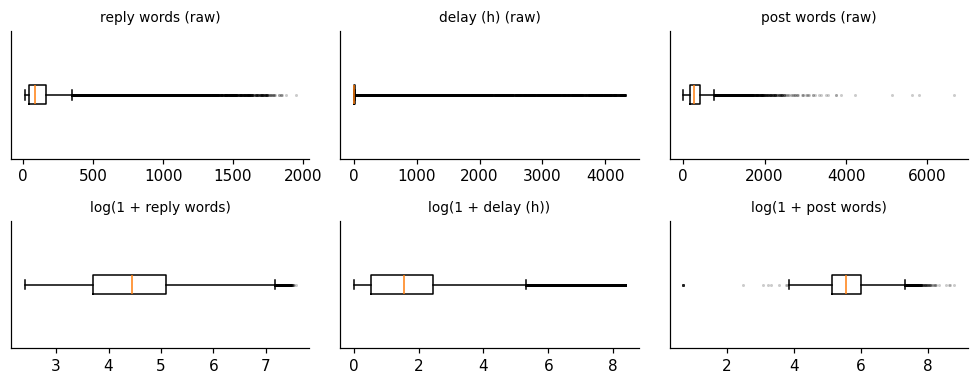

Takeaway: lengths are right-skewed with 6-9% of points past the fence; after log(1+x) skew is near 0 and few points remain outside.


In [11]:
def shape(x):
    q1, q3 = np.percentile(x, [25, 75]); fence = q3 + 1.5 * (q3 - q1)
    return {'median': np.median(x), 'Q3': q3, 'upper fence': fence, '% beyond fences': np.mean((x > fence) | (x < q1 - 1.5 * (q3 - q1))),
            'skewness': stats.skew(x), 'max': np.max(x)}
cols = {'reply words': A.words, 'delay (h)': A.delay_h, 'post words': THREADS.post_words}
O = pd.DataFrame({(k, f): shape(f_(v.values)) for k, v in cols.items() for f, f_ in [('raw', lambda z: z), ('log(1+x)', np.log1p)]}).T
display(O.style.format({'median': '{:.2f}', 'Q3': '{:.2f}', 'upper fence': '{:.2f}', '% beyond fences': '{:.1%}', 'skewness': '{:.2f}', 'max': '{:,.1f}'}))
fig, ax = plt.subplots(2, 3, figsize=(9, 3.6))
for j, (k, v) in enumerate(cols.items()):
    ax[0, j].boxplot(v, vert=False, flierprops={'markersize': 1, 'alpha': .2}); ax[0, j].set_title(k + ' (raw)', fontsize=9)
    ax[1, j].boxplot(np.log1p(v), vert=False, flierprops={'markersize': 1, 'alpha': .2}); ax[1, j].set_title(f'log(1 + {k})', fontsize=9)
    for a in ax[:, j]: a.set_yticks([])
fig.tight_layout(); fig.savefig(FIG_DIR / 'outliers_boxplots.png', dpi=200); plt.show()
print('Takeaway: lengths are right-skewed with 6-9% of points past the fence; after log(1+x) skew is near 0 and few points remain outside.')

**We keep the outliers and work on the log scale.** A 1,500-word reply or a 2,000-word post is real behaviour, not an error, so deleting or capping it would change the data. Reddit already caps comment length (10,000 characters), so there are no absurd values. Taking `log(1+x)` brings the skew close to 0. It also turns differences into ratios ("winning replies are 1.7× as long"), which is easier to interpret. Delay is very skewed, so we never average it; the tests use it in bins.

### 3.6 Encoding and the size check
`has_link` is already 0/1. The delay is binned into five intervals (Lecture 2: one-hot for categories) for the χ² comparison in Test 2. Counts stay counts.

In [12]:
DELAY_BINS, DELAY_LABELS = [-np.inf, 1, 3, 6, 24, np.inf], ['<1h', '1-3h', '3-6h', '6-24h', '>24h']
A['delay_bin'] = pd.cut(A.delay_h, DELAY_BINS, labels=DELAY_LABELS)
A['log_words'] = np.log1p(A.words)
X = pd.concat([A[['words', 'log_words', 'delay_h', 'has_link', 'post_words', 'won']].astype(float),
               pd.get_dummies(A.delay_bin, prefix='delay', dtype=float)], axis=1)
print(f'Encoded table: {X.shape[0]:,} replies x {X.shape[1]} attributes = {X.shape[0] * X.shape[1]:,}  (>= 3,000,000: {X.size >= 3_000_000})')
print('Attributes:', list(X.columns))

Encoded table: 479,276 replies x 11 attributes = 5,272,036  (>= 3,000,000: True)
Attributes: ['words', 'log_words', 'delay_h', 'has_link', 'post_words', 'won', 'delay_<1h', 'delay_1-3h', 'delay_3-6h', 'delay_6-24h', 'delay_>24h']


---
## 4. Before vs. after preparation

In [13]:
pd.DataFrame({
  'measure': ['rows', 'fields', 'time span', 'duplicate comment IDs', 'missing or unusable text', 'outcome column', 'ID format'],
  'before (raw)': [f'{len(posts):,} posts, {n:,} comments', f'{len(sub_fields)} post / {len(com_fields)} comment',
                   '2013-01 to 2025-12', f'{n_dup:,}', f'{posts.post_removed.mean():.0%} of posts, {E.removed.mean():.0%} of comments',
                   'none (Δ only inside text)', 'base-36 strings, base-10 ints after 2023'],
  'after': [f'{len(A):,} replies in {A.link.nunique():,} threads', f'{X.shape[1]} encoded', '2017-04 to 2022-11', '0', '0',
            f"won (0/1): {int(A.won.sum()):,} winners", 'one integer ID'],
}).style.hide(axis='index')

measure,before (raw),after
rows,"345,098 posts, 18,644,355 comments","479,276 replies in 25,439 threads"
fields,132 post / 81 comment,11 encoded
time span,2013-01 to 2025-12,2017-04 to 2022-11
duplicate comment IDs,"2,508",0
missing or unusable text,"66% of posts, 8% of comments",0
outcome column,none (Δ only inside text),"won (0/1): 42,197 winners"
ID format,"base-36 strings, base-10 ints after 2023",one integer ID


---
## 5. Exploratory data analysis

**Basic questions**
1. How long are replies, and how soon after the post do they arrive?
2. How many OPs award a delta at all, and has that changed over the years?
3. How many replies win in a thread where the OP does award?

In [14]:
print(f'Replies: median {A.words.median():.0f} words (IQR {A.words.quantile(.25):.0f}-{A.words.quantile(.75):.0f}); '
      f'median delay {A.delay_h.median():.1f} h; {A.has_link.mean():.1%} contain a link.')
print(f'OPs who award a delta: {THREADS.op_awarded.mean():.1%} of {len(THREADS):,} intact threads.')
per = A.groupby('link').won.agg(['sum', 'size'])
print(f'Awarding threads: median {per["size"].median():.0f} replies and {per["sum"].median():.0f} winner; overall {A.won.mean():.1%} of replies win.')
by_year = A.groupby('year').agg(replies=('won', 'size'), win_rate=('won', 'mean'),
                                replies_per_thread=('link', lambda s: len(s) / s.nunique()))
by_year['OPs who award'] = THREADS.groupby(pd.to_datetime(THREADS.created, unit='s').dt.year).op_awarded.mean()
display(by_year.style.format({'replies': '{:,}', 'win_rate': '{:.1%}', 'replies_per_thread': '{:.1f}', 'OPs who award': '{:.1%}'}))
print('Takeaway: threads got bigger every year, so the win rate per reply falls, while the share of OPs who award stays level.')

Replies: median 84 words (IQR 40-163); median delay 3.8 h; 6.2% contain a link.
OPs who award a delta: 57.6% of 44,160 intact threads.
Awarding threads: median 12 replies and 1 winner; overall 8.8% of replies win.


,replies,win_rate,replies_per_thread,OPs who award
year,,,,
2017,"44,430",12.3%,12.8,54.2%
2018,"80,072",10.9%,14.7,54.9%
2019,"68,645",9.5%,16.6,56.2%
2020,"97,367",8.7%,19.7,57.7%
2021,"109,245",7.2%,24.2,62.3%
2022,"79,517",6.5%,27.1,63.2%


Takeaway: threads got bigger every year, so the win rate per reply falls, while the share of OPs who award stays level.


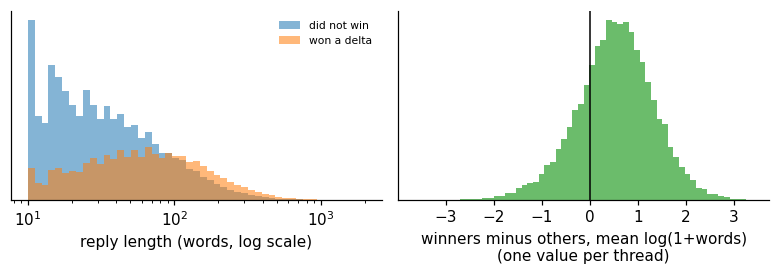

Takeaway: winning replies are longer, and inside the same thread the winners are longer in 76% of threads.


In [15]:
g = A.groupby(['link', 'won']).log_words.mean().unstack().dropna()
d_len = g[1] - g[0]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
bins = np.logspace(1, np.log10(2000), 50)
for k, lab, c in [(0, 'did not win', 'tab:blue'), (1, 'won a delta', 'tab:orange')]:
    ax[0].hist(A.words[A.won == k], bins=bins, density=True, alpha=.55, label=lab, color=c)
ax[0].set_xscale('log'); ax[0].set_xlabel('reply length (words, log scale)'); ax[0].set_yticks([]); ax[0].legend(fontsize=7, frameon=False)
ax[1].hist(d_len, bins=60, color='tab:green', alpha=.7); ax[1].axvline(0, color='k', lw=1)
ax[1].set_xlabel('winners minus others, mean log(1+words)\n(one value per thread)'); ax[1].set_yticks([])
fig.tight_layout(); fig.savefig(FIG_DIR / 'length.png', dpi=220); plt.show()
print(f'Takeaway: winning replies are longer, and inside the same thread the winners are longer in {(d_len > 0).mean():.0%} of threads.')

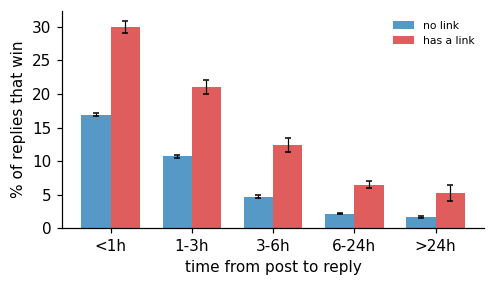

Takeaway: the win rate falls from 17.9% in the first hour to 1.8% after a day, and replies with a link win more at every delay.


In [16]:
def rate_ci(s):
    p, m = s.mean(), len(s); se = np.sqrt(p * (1 - p) / m)
    return pd.Series({'rate': p, 'lo': p - 1.96 * se, 'hi': p + 1.96 * se, 'n': m})
tab = A.groupby(['delay_bin', 'has_link'], observed=True).won.apply(rate_ci).unstack()
fig, ax = plt.subplots(figsize=(4.6, 2.7))
xs = np.arange(len(DELAY_LABELS))
for off, hl, lab, c in [(-.18, False, 'no link', 'tab:blue'), (.18, True, 'has a link', 'tab:red')]:
    t = tab.xs(hl, level='has_link')
    ax.bar(xs + off, 100 * t.rate, width=.36, color=c, alpha=.75, label=lab,
           yerr=[100 * (t.rate - t.lo), 100 * (t.hi - t.rate)], capsize=2, error_kw={'lw': .8})
ax.set_xticks(xs, DELAY_LABELS); ax.set_xlabel('time from post to reply'); ax.set_ylabel('% of replies that win')
ax.legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / 'delay_link.png', dpi=220); plt.show()
r = A.groupby('delay_bin', observed=True).won.mean()
print(f'Takeaway: the win rate falls from {r.iloc[0]:.1%} in the first hour to {r.iloc[-1]:.1%} after a day, and replies with a link win more at every delay.')

**Our problem statements** (the basic questions describe replies one at a time; ours compare replies that the *same* OP judged, and need the delta label that we rebuilt in 3.1):
- **P1 (primary).** Within the same thread, are the replies that win a delta longer than the ones that don't?
- **P2.** Do replies that arrive within the first 3 hours win more often? (CMV's Rule E asks the OP to be around for the first 3 hours.)
- **P3.** Do replies that link to a source win more often?
- **P4.** Thread level: do OPs who explain their view at greater length award a delta more often, or less?

---
## 6. Hypothesis testing
The test statistics are written out from the lecture formulas (estimate − null value, divided by its standard error) and checked against `scipy`. For each test the hypotheses, α, sidedness and the smallest difference that matters are fixed in the markdown **before** the code runs.

**Smallest difference that matters.** We use one yardstick everywhere: a **20% relative difference**. For lengths, that means a ratio of 1.20, about one extra sentence on a typical 80-word reply. For win rates, it means 2 percentage points, roughly 20% of the 8.8% base rate. Anything smaller would not change the advice we would give someone posting a reply.

In [17]:
def fmt_p(p):
    return '< 1e-300' if p < 1e-300 else f'{p:.2e}'

def paired_t(d):                                   # Lecture 7: t = dbar / (s_d / sqrt(n)), df = n - 1
    n, dbar, s = len(d), d.mean(), d.std(ddof=1); se = s / np.sqrt(n); df = n - 1; tc = stats.t.ppf(.975, df)
    return {'n': n, 'est': dbar, 'se': se, 't': dbar / se, 'df': df, 'ci': (dbar - tc * se, dbar + tc * se)}

def welch_t(x, y):                                 # unequal variances, Welch-Satterthwaite df
    vx, vy, nx, ny = x.var(ddof=1), y.var(ddof=1), len(x), len(y)
    se = np.sqrt(vx / nx + vy / ny); df = se**4 / ((vx / nx)**2 / (nx - 1) + (vy / ny)**2 / (ny - 1))
    est = x.mean() - y.mean(); tc = stats.t.ppf(.975, df)
    return {'est': est, 'se': se, 't': est / se, 'df': df, 'ci': (est - tc * se, est + tc * se)}

def pooled_t(x, y):                                # Lecture 7: pooled s^2, df = n1 + n2 - 2
    nx, ny = len(x), len(y); sp2 = ((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2)
    se = np.sqrt(sp2 * (1 / nx + 1 / ny)); return {'t': (x.mean() - y.mean()) / se, 'df': nx + ny - 2}

def f_test(x, y):                                  # Lecture 7/8: F = s1^2 / s2^2, two-sided
    F, d1, d2 = x.var(ddof=1) / y.var(ddof=1), len(x) - 1, len(y) - 1
    return {'F': F, 'df': (d1, d2), 'p': 2 * min(stats.f.sf(F, d1, d2), stats.f.cdf(F, d1, d2))}

def two_prop_z(k1, n1, k2, n2):                    # Lecture 7: pooled p for the test, unpooled SE for the CI
    p1, p2, p = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2)); se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {'p1': p1, 'p2': p2, 'est': p1 - p2, 'z': z, 'ci': (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se)}

def chi2_indep(O):                                 # Lecture 8: E_ij = row_i * col_j / N, df = (r-1)(c-1)
    O = np.asarray(O, float); Ex = O.sum(1, keepdims=True) * O.sum(0, keepdims=True) / O.sum()
    chi2 = ((O - Ex)**2 / Ex).sum(); df = (O.shape[0] - 1) * (O.shape[1] - 1)
    return {'chi2': chi2, 'df': df, 'p': stats.chi2.sf(chi2, df)}

# sanity check against scipy on a small random sample
rng = np.random.default_rng(0); a_, b_ = rng.normal(0, 1, 300), rng.normal(.2, 1.5, 200)
assert np.isclose(paired_t(a_[:200] - b_)['t'], stats.ttest_rel(a_[:200], b_).statistic)
assert np.isclose(welch_t(a_, b_)['t'], stats.ttest_ind(a_, b_, equal_var=False).statistic)
assert np.isclose(pooled_t(a_, b_)['t'], stats.ttest_ind(a_, b_).statistic)
assert np.isclose(chi2_indep([[30, 70], [45, 55]])['chi2'], stats.chi2_contingency([[30, 70], [45, 55]], correction=False)[0])
print('formulas match scipy')

formulas match scipy


### Test 1 (P1): within a thread, are winning replies longer?
| | |
|---|---|
| H₀ | μ_d ≤ 0 |
| H₁ | μ_d > 0 |
| α | 0.05 |
| Side | one-sided (right) |
| Test | paired t-test |
| Smallest difference that matters | winners 20% longer, i.e. μ_d ≥ ln 1.20 = 0.182 |

For each thread with at least one winning and one losing reply, *d* = mean log(1+words) of the winners − mean log(1+words) of the others; μ_d is the mean of *d* over threads. **Why paired:** the two groups come from the same thread, judged by the same OP on the same topic, just as a patient is measured before and after. Pairing removes everything that differs between threads (topic, OP, how busy the thread was). *d* is close to symmetric (see Fig. length.png) and n is in the tens of thousands, so the CLT (Lecture 4) makes the t-test safe even though word counts are skewed.

In [18]:
t1 = paired_t(d_len.values)
p1 = stats.t.sf(t1['t'], t1['df'])
ratio = np.exp([t1['est'], *t1['ci']])
print(f"threads (pairs) n = {t1['n']:,}")
print(f"mean d = {t1['est']:.3f} log-units  ->  winners are {ratio[0]:.2f}x as long, 95% CI [{ratio[1]:.2f}, {ratio[2]:.2f}]")
print(f"t = {t1['t']:.1f}, df = {t1['df']:,}, one-sided p = {fmt_p(p1)} -> {'reject H0' if p1 < ALPHA else 'fail to reject H0'}")
print(f"meaningful (whole CI above 1.20): {ratio[1] > 1.20};  skewness of d = {stats.skew(d_len):.2f}")

# other tests we considered, run for comparison: ignore the pairing and compare all winners with all others
w1, w0 = A.log_words[A.won == 1], A.log_words[A.won == 0]
ft, wt, pt = f_test(w1, w0), welch_t(w1, w0), pooled_t(w1, w0)
print(f"\nF-test for equal variances: F = {ft['F']:.3f}, df = ({ft['df'][0]:,}, {ft['df'][1]:,}), p = {fmt_p(ft['p'])}")
print(f"Welch t (unpaired): ratio {np.exp(wt['est']):.2f}, t = {wt['t']:.1f}, df = {wt['df']:,.0f}")
print(f"Pooled t (unpaired): t = {pt['t']:.1f}, df = {pt['df']:,}")

threads (pairs) n = 23,055
mean d = 0.519 log-units  ->  winners are 1.68x as long, 95% CI [1.66, 1.70]
t = 98.4, df = 23,054, one-sided p = < 1e-300 -> reject H0
meaningful (whole CI above 1.20): True;  skewness of d = -0.20

F-test for equal variances: F = 0.833, df = (42,196, 437,078), p = 8.92e-135
Welch t (unpaired): ratio 1.77, t = 126.8, df = 52,475
Pooled t (unpaired): t = 117.6, df = 479,274


### Test 2 (P2): do replies in the first 3 hours win more often?
| | |
|---|---|
| H₀ | p_early − p_late ≤ 0 |
| H₁ | p_early − p_late > 0 |
| α | 0.05 |
| Side | one-sided (right) |
| Test | two-proportion z-test |
| Smallest difference that matters | 2 percentage points |

p_early, p_late: share of replies that win, among replies posted ≤ 3 h after the post and after that. The 3-hour cut is CMV's own (Rule E asks OPs to engage within 3 hours); it is also close to the median delay, so the two groups are similar in size. Two proportions from large groups (well over 15 successes and failures in each), so the z-test fits.

In [19]:
early = A.delay_h <= 3
t2 = two_prop_z(A.won[early].sum(), early.sum(), A.won[~early].sum(), (~early).sum())
p2 = stats.norm.sf(t2['z'])
print(f"early: {early.sum():,} replies, win rate {t2['p1']:.2%};  late: {(~early).sum():,} replies, win rate {t2['p2']:.2%}")
print(f"difference = {100*t2['est']:.2f} points, 95% CI [{100*t2['ci'][0]:.2f}, {100*t2['ci'][1]:.2f}]")
print(f"z = {t2['z']:.1f}, one-sided p = {fmt_p(p2)} -> {'reject H0' if p2 < ALPHA else 'fail to reject H0'};  meaningful (CI above 2 points): {t2['ci'][0] > .02}")

# comparisons: chi-square over all five delay bins, and a paired t across threads (deals with replies sharing a thread)
O = pd.crosstab(A.delay_bin, A.won)
c2 = chi2_indep(O.values)
print(f"\nchi-square independence, 5 delay bins x won: chi2 = {c2['chi2']:,.0f}, df = {c2['df']}, p = {fmt_p(c2['p'])}")
print('win rate by bin:', (A.groupby('delay_bin', observed=True).won.mean() * 100).round(1).to_dict())
print(f"z^2 = {t2['z']**2:,.0f} equals the 2x2 chi-square: {chi2_indep(pd.crosstab(early, A.won).values)['chi2']:,.0f}")
th = A.groupby(['link', early]).won.mean().unstack().dropna()
pt2 = paired_t((th[True] - th[False]).values)
print(f"paired t over {pt2['n']:,} threads (early rate - late rate): mean {100*pt2['est']:.2f} points, t = {pt2['t']:.1f}, df = {pt2['df']:,}")

early: 219,836 replies, win rate 15.63%;  late: 259,440 replies, win rate 3.02%
difference = 12.61 points, 95% CI [12.45, 12.78]
z = 153.5, one-sided p = < 1e-300 -> reject H0;  meaningful (CI above 2 points): True



chi-square independence, 5 delay bins x won: chi2 = 26,641, df = 4, p = < 1e-300


win rate by bin: {'<1h': 17.9, '1-3h': 11.5, '3-6h': 5.2, '6-24h': 2.3, '>24h': 1.8}


z^2 = 23,570 equals the 2x2 chi-square: 23,570
paired t over 22,782 threads (early rate - late rate): mean 13.26 points, t = 80.1, df = 22,781


### Test 3 (P3): do replies with a link win more often?
| | |
|---|---|
| H₀ | p_link − p_none ≤ 0 |
| H₁ | p_link − p_none > 0 |
| α | 0.05 |
| Side | one-sided (right) |
| Test | two-proportion z-test |
| Smallest difference that matters | 2 percentage points |

A link usually points to a source or evidence; Tan et al. (2016) found that successful CMV arguments use more of them, so we expect a positive gap. Replies with links are also longer, so we repeat the test within length quartiles to check that the gap is not just length.

In [20]:
hl = A.has_link
t3 = two_prop_z(A.won[hl].sum(), hl.sum(), A.won[~hl].sum(), (~hl).sum())
p3 = stats.norm.sf(t3['z'])
print(f"with link: {hl.sum():,} replies, win rate {t3['p1']:.2%};  without: {(~hl).sum():,}, win rate {t3['p2']:.2%}")
print(f"difference = {100*t3['est']:.2f} points, 95% CI [{100*t3['ci'][0]:.2f}, {100*t3['ci'][1]:.2f}]")
print(f"z = {t3['z']:.1f}, one-sided p = {fmt_p(p3)} -> {'reject H0' if p3 < ALPHA else 'fail to reject H0'};  meaningful (CI above 2 points): {t3['ci'][0] > .02}")
c3 = chi2_indep(pd.crosstab(hl, A.won).values)
print(f"\n2x2 chi-square: chi2 = {c3['chi2']:,.0f}, df = 1 (= z^2 = {t3['z']**2:,.0f})")
A['len_q'] = pd.qcut(A.words, 4)
rows = []
for qq, g_ in A.groupby('len_q', observed=True):
    h = g_.has_link; r_ = two_prop_z(g_.won[h].sum(), h.sum(), g_.won[~h].sum(), (~h).sum())
    rows.append({'length quartile (words)': str(qq), 'with link': r_['p1'], 'without': r_['p2'], 'difference (points)': 100 * r_['est'], 'z': r_['z']})
pd.DataFrame(rows).style.format({'with link': '{:.1%}', 'without': '{:.1%}', 'difference (points)': '{:.1f}', 'z': '{:.1f}'}).hide(axis='index')

with link: 29,653 replies, win rate 18.43%;  without: 449,623, win rate 8.17%
difference = 10.26 points, 95% CI [9.81, 10.71]
z = 60.4, one-sided p = < 1e-300 -> reject H0;  meaningful (CI above 2 points): True

2x2 chi-square: chi2 = 3,645, df = 1 (= z^2 = 3,645)


length quartile (words),with link,without,difference (points),z
"(9.999, 40.0]",8.5%,3.1%,5.4,17.9
"(40.0, 84.0]",14.7%,6.1%,8.6,23.8
"(84.0, 163.0]",17.6%,9.8%,7.9,21.0
"(163.0, 1949.0]",22.6%,14.5%,8.1,25.2


### Test 4 (P4): do OPs with longer posts award deltas more often?
| | |
|---|---|
| H₀ | μ_award − μ_none = 0 |
| H₁ | μ_award − μ_none ≠ 0 |
| α | 0.05 |
| Side | two-sided |
| Test | Welch t-test (F-test first) |
| Smallest difference that matters | posts 20% longer, i.e. a gap of ln 1.20 = 0.182 |

Unit: one intact thread (Section 3.3, before the "OP awarded" filter). μ: mean log(1+post words) for OPs who awarded at least one delta and for those who did not. Two-sided, because it could go either way: a long post may show an OP who has thought it through and is open, or one who is soapboxing (Rule B). Two separate groups and an unknown σ call for a two-sample t-test; following Lecture 8 we test the variances first to choose between the pooled and Welch versions.

In [21]:
lp = np.log1p(THREADS.post_words)
a1, a0 = lp[THREADS.op_awarded], lp[~THREADS.op_awarded]
ft4 = f_test(a1, a0)
print(f"F-test: F = {ft4['F']:.3f}, df = ({ft4['df'][0]:,}, {ft4['df'][1]:,}), p = {fmt_p(ft4['p'])} -> "
      f"{'variances differ: use Welch' if ft4['p'] < ALPHA else 'no evidence variances differ'}")
t4 = welch_t(a1, a0); p4 = 2 * stats.t.sf(abs(t4['t']), t4['df'])
r4 = np.exp([t4['est'], *t4['ci']])
print(f"awarded: {len(a1):,} threads, median {THREADS.post_words[THREADS.op_awarded].median():.0f} words;  "
      f"not: {len(a0):,}, median {THREADS.post_words[~THREADS.op_awarded].median():.0f} words")
print(f"ratio of (geometric) mean post length = {r4[0]:.3f}, 95% CI [{r4[1]:.3f}, {r4[2]:.3f}]")
print(f"Welch t = {t4['t']:.2f}, df = {t4['df']:,.0f}, two-sided p = {fmt_p(p4)} -> {'reject H0' if p4 < ALPHA else 'fail to reject H0'}")
print(f"meaningful (CI outside [1/1.20, 1.20]): {r4[1] > 1.2 or r4[2] < 1/1.2}")
pt4 = pooled_t(a1, a0)
print(f"\npooled t (for comparison): t = {pt4['t']:.2f}, df = {pt4['df']:,}")
long_ = THREADS.post_words > THREADS.post_words.median()
z4 = two_prop_z(THREADS.op_awarded[long_].sum(), long_.sum(), THREADS.op_awarded[~long_].sum(), (~long_).sum())
print(f"two-proportion z, award rate for posts above vs below the median length: {z4['p1']:.1%} vs {z4['p2']:.1%}, z = {z4['z']:.1f}")

F-test: F = 0.955, df = (25,446, 18,712), p = 6.72e-04 -> variances differ: use Welch
awarded: 25,447 threads, median 270 words;  not: 18,713, median 248 words
ratio of (geometric) mean post length = 1.068, 95% CI [1.056, 1.081]
Welch t = 10.99, df = 39,789, two-sided p = 4.52e-28 -> reject H0
meaningful (CI outside [1/1.20, 1.20]): False

pooled t (for comparison): t = 11.03, df = 44,158
two-proportion z, award rate for posts above vs below the median length: 60.1% vs 55.2%, z = 10.4


---
## 7. Summary

In [22]:
summary = pd.DataFrame([
    ['1 Length, within thread', 'paired t', f"{t1['t']:.1f} ({t1['df']:,})", fmt_p(p1), f"{ratio[0]:.2f}x [{ratio[1]:.2f}, {ratio[2]:.2f}]", ratio[1] > 1.2],
    ['2 First 3 hours', '2-prop z', f"{t2['z']:.1f}", fmt_p(p2), f"+{100*t2['est']:.1f} pts [{100*t2['ci'][0]:.1f}, {100*t2['ci'][1]:.1f}]", t2['ci'][0] > .02],
    ['3 Has a link', '2-prop z', f"{t3['z']:.1f}", fmt_p(p3), f"+{100*t3['est']:.1f} pts [{100*t3['ci'][0]:.1f}, {100*t3['ci'][1]:.1f}]", t3['ci'][0] > .02],
    ['4 OP post length', 'Welch t', f"{t4['t']:.1f} ({t4['df']:,.0f})", fmt_p(p4), f"{r4[0]:.3f}x [{r4[1]:.3f}, {r4[2]:.3f}]", r4[1] > 1.2 or r4[2] < 1/1.2],
], columns=['test', 'method', 'statistic (df)', 'p-value', 'estimate [95% CI]', 'matters?'])
summary['decision'] = ['reject H0' if float(p.replace('< ', '')) < ALPHA else 'fail to reject' for p in summary['p-value']]
summary.style.hide(axis='index')

test,method,statistic (df),p-value,estimate [95% CI],matters?,decision
"1 Length, within thread",paired t,"98.4 (23,054)",< 1e-300,"1.68x [1.66, 1.70]",True,reject H0
2 First 3 hours,2-prop z,153.5,< 1e-300,"+12.6 pts [12.4, 12.8]",True,reject H0
3 Has a link,2-prop z,60.4,< 1e-300,"+10.3 pts [9.8, 10.7]",True,reject H0
4 OP post length,Welch t,"11.0 (39,789)",4.52e-28,"1.068x [1.056, 1.081]",False,reject H0


**Takeaways**
1. **Length.** Inside the same thread, the replies that win are about 1.7× as long as the ones that don't, and they are longer in roughly three threads out of four.
2. **Timing.** Replies in the first 3 hours win about five times as often as later ones. The rate falls steadily with every delay bin, and the gap holds when each thread is compared with itself.
3. **Evidence.** Replies with a link win about twice as often. This holds within every length quartile, so it is not just that linked replies are longer.
4. **The OP.** OPs who award deltas write slightly longer posts, about 7% longer. The difference is statistically clear but well under our 20% bar, so post length says little about how open an OP is.